# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Stay Listings Dataset](https://www.kaggle.com/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays?select=stay_listings.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

/kaggle/input/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays/README.md
/kaggle/input/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays/datasheet.md
/kaggle/input/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays/stay_listings.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('stay_listings.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,...,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
0,L00001,Mexico City,Entire home,2,1.5,5,7.1,52.0,17.0,1,...,6.9,27,23,0,30,4.59,3,61.3,11500.0,0
1,L00002,Paris,Entire home,1,1.0,3,4.6,147.0,52.0,0,...,1.4,13,20,1,7,4.61,7,23.7,11300.0,0
2,L00003,New York,Entire home,2,2.0,5,1.6,131.0,36.0,0,...,5.1,18,35,0,30,4.64,6,45.8,21700.0,0
3,L00004,Tokyo,Entire home,2,1.5,5,5.7,164.0,68.0,0,...,3.6,36,43,0,2,4.71,20,42.6,25300.0,0
4,L00005,Berlin,Entire home,3,2.0,8,4.6,321.0,32.0,1,...,5.6,27,48,1,5,4.98,28,65.1,74500.0,0


## last Five row

In [4]:
df.tail()

,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,...,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
9995,L09996,Berlin,Private room,1,1.5,4,1.4,43.0,16.0,1,...,1.0,3,25,1,5,4.44,17,43.1,6300.0,0
9996,L09997,Sydney,Entire home,2,2.0,6,4.7,80.0,39.0,0,...,4.1,8,15,0,1,4.22,6,14.3,4000.0,0
9997,L09998,London,Entire home,2,2.0,6,1.9,215.0,29.0,0,...,0.5,20,42,0,2,4.82,25,52.2,39100.0,0
9998,L09999,London,Entire home,2,2.0,6,3.1,109.0,48.0,0,...,0.4,14,31,0,2,4.45,39,30.4,11800.0,0
9999,L10000,Lisbon,Private room,1,1.5,4,9.1,22.0,7.0,1,...,0.7,41,12,0,1,4.40,59,61.7,4800.0,0


## Shape of our dataset

In [5]:
df.shape

(10000, 21)

## List out all columns

In [6]:
df.columns

Index(['listing_id', 'city', 'property_type', 'bedrooms', 'bathrooms',
       'guest_capacity', 'distance_center_km', 'price_per_night_usd',
       'cleaning_fee_usd', 'superhost', 'host_response_rate', 'host_years',
       'photo_count', 'amenities_count', 'instant_book', 'min_nights',
       'review_score', 'reviews_count', 'occupancy_rate_pct',
       'annual_revenue_usd', 'high_demand'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

listing_id              object
city                    object
property_type           object
bedrooms                 int64
bathrooms              float64
guest_capacity           int64
distance_center_km     float64
price_per_night_usd    float64
cleaning_fee_usd       float64
superhost                int64
host_response_rate     float64
host_years             float64
photo_count              int64
amenities_count          int64
instant_book             int64
min_nights               int64
review_score           float64
reviews_count            int64
occupancy_rate_pct     float64
annual_revenue_usd     float64
high_demand              int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           10000 non-null  object 
 1   city                 10000 non-null  object 
 2   property_type        10000 non-null  object 
 3   bedrooms             10000 non-null  int64  
 4   bathrooms            10000 non-null  float64
 5   guest_capacity       10000 non-null  int64  
 6   distance_center_km   10000 non-null  float64
 7   price_per_night_usd  10000 non-null  float64
 8   cleaning_fee_usd     10000 non-null  float64
 9   superhost            10000 non-null  int64  
 10  host_response_rate   10000 non-null  float64
 11  host_years           10000 non-null  float64
 12  photo_count          10000 non-null  int64  
 13  amenities_count      10000 non-null  int64  
 14  instant_book         10000 non-null  int64  
 15  min_nights           10000 non-null  

## Check Null Value

In [9]:
df.isnull().sum()

listing_id             0
city                   0
property_type          0
bedrooms               0
bathrooms              0
guest_capacity         0
distance_center_km     0
price_per_night_usd    0
cleaning_fee_usd       0
superhost              0
host_response_rate     0
host_years             0
photo_count            0
amenities_count        0
instant_book           0
min_nights             0
review_score           0
reviews_count          0
occupancy_rate_pct     0
annual_revenue_usd     0
high_demand            0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,host_response_rate,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.406600,1.563800,4.327500,4.109520,91.666300,27.487600,0.361700,91.728000,3.175140,22.053600,28.208400,0.4460,5.056100,4.599185,49.210400,52.994650,16125.830000,0.250400
std,0.936143,0.499354,1.942375,3.730051,45.596351,18.061541,0.480517,5.791474,2.822191,9.268696,9.509943,0.4971,8.383781,0.188447,43.691224,19.478673,9699.187762,0.433265
min,0.000000,0.500000,1.000000,0.200000,18.000000,2.000000,0.000000,66.000000,0.200000,3.000000,3.000000,0.0000,1.000000,3.880000,0.000000,3.000000,400.000000,0.000000
25%,1.000000,1.000000,3.000000,1.800000,59.000000,15.000000,0.000000,88.000000,1.100000,16.000000,22.000000,0.0000,1.000000,4.470000,18.000000,39.600000,9500.000000,0.000000
50%,1.000000,1.500000,4.000000,3.000000,82.000000,23.000000,0.000000,92.000000,2.300000,22.000000,28.000000,0.0000,2.000000,4.600000,38.000000,52.900000,13950.000000,0.000000
75%,2.000000,2.000000,5.000000,5.100000,114.000000,36.000000,1.000000,96.000000,4.400000,28.000000,35.000000,1.0000,3.000000,4.730000,67.000000,66.600000,20500.000000,1.000000
max,4.000000,3.500000,10.000000,30.000000,414.000000,164.000000,1.000000,100.000000,14.000000,55.000000,65.000000,1.0000,30.000000,5.000000,417.000000,98.000000,85500.000000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

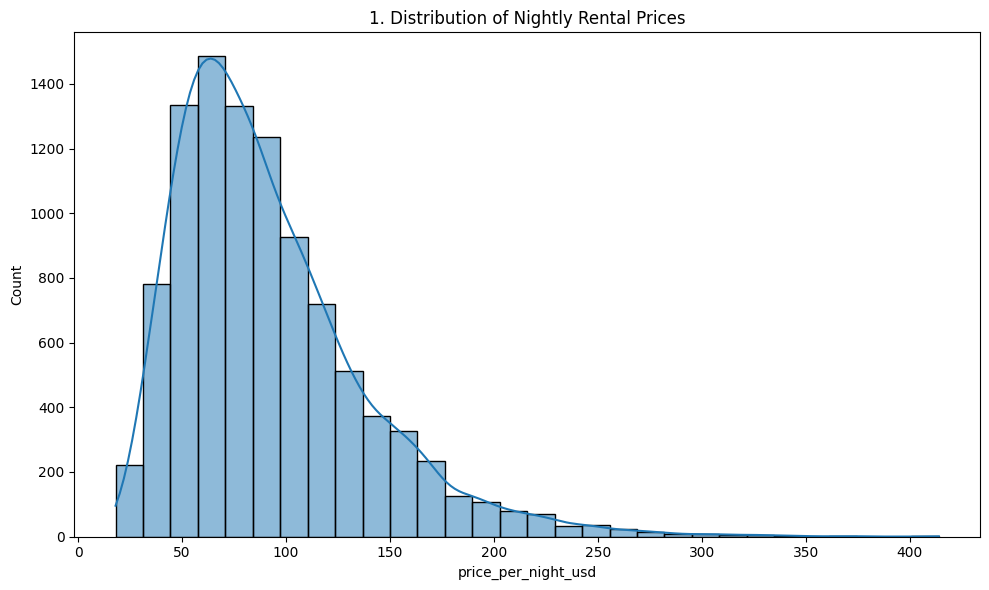

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='price_per_night_usd', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Nightly Rental Prices')
show_fig()
plot_no += 1

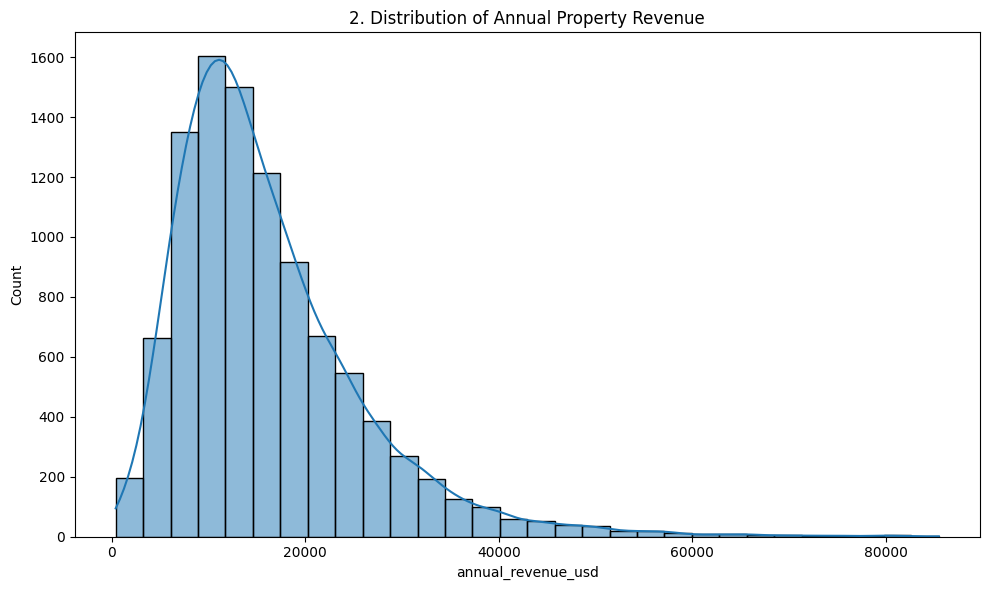

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='annual_revenue_usd', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Annual Property Revenue')
show_fig()
plot_no += 1

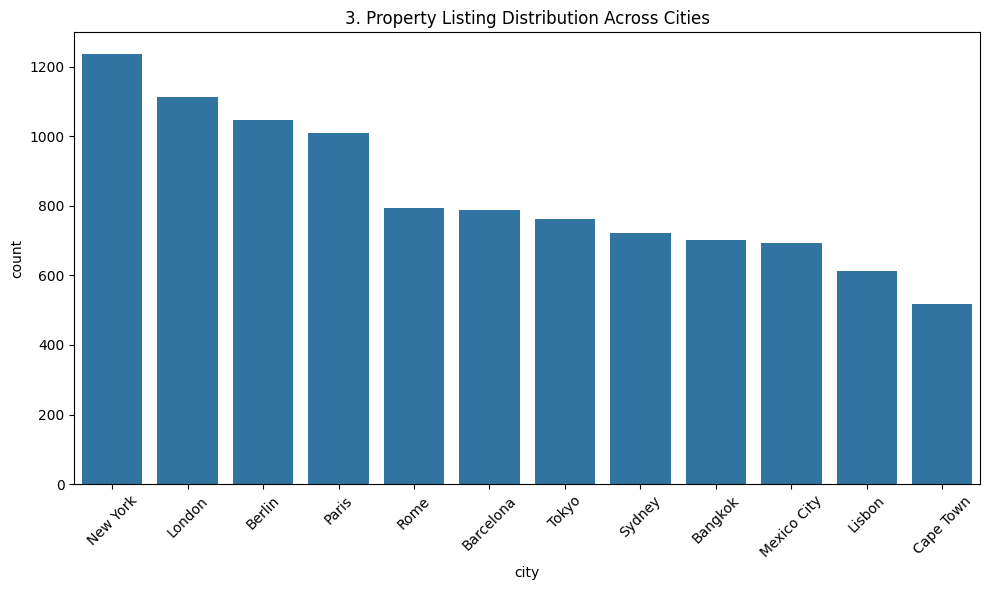

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='city', order=df['city'].value_counts().index)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Property Listing Distribution Across Cities')
show_fig()
plot_no += 1

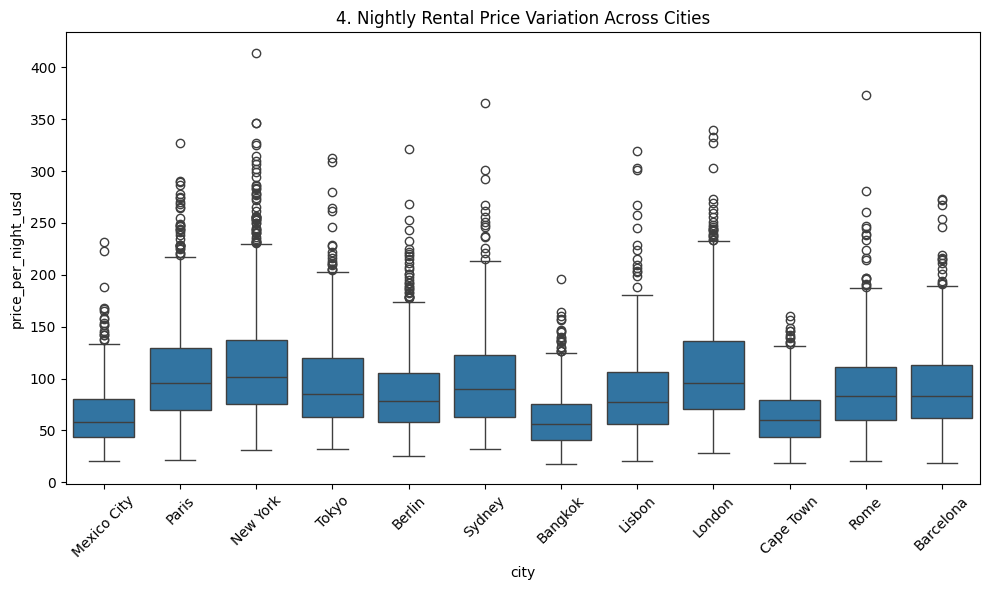

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='city', y='price_per_night_usd')
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Nightly Rental Price Variation Across Cities')
show_fig()
plot_no += 1

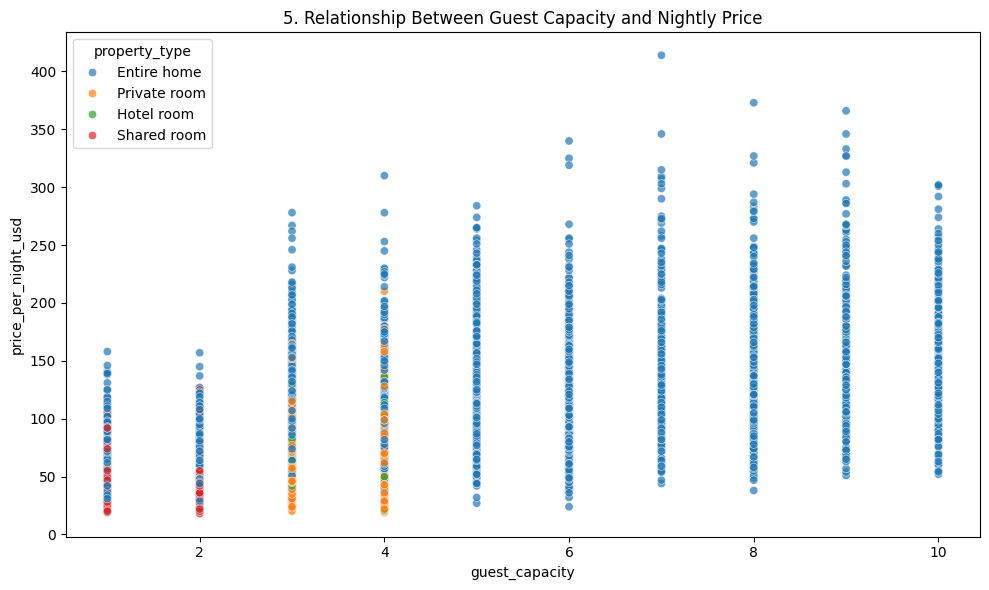

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='guest_capacity', y='price_per_night_usd', hue='property_type', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Guest Capacity and Nightly Price')
show_fig()
plot_no += 1

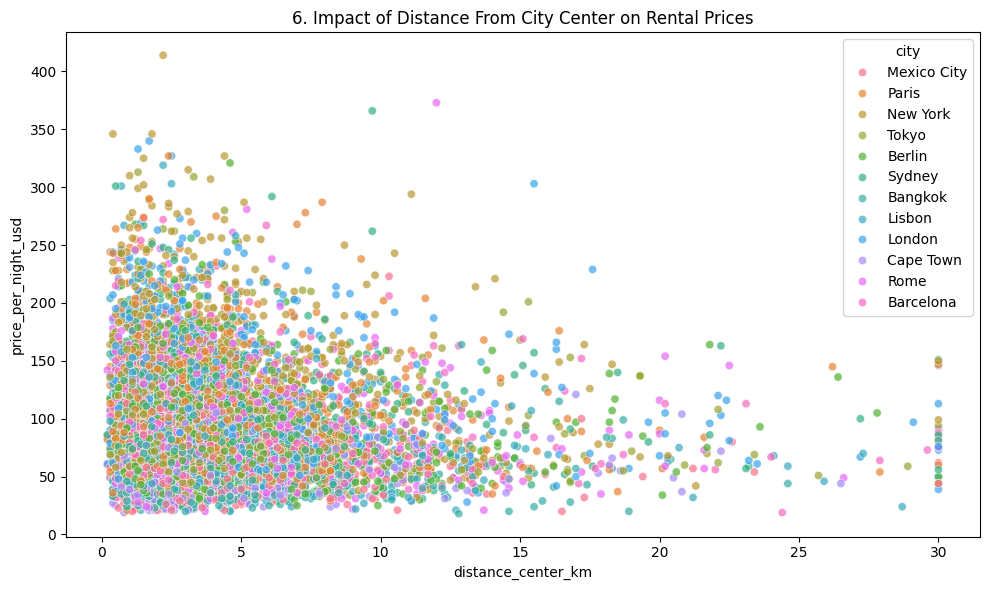

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='distance_center_km', y='price_per_night_usd', hue='city', alpha=0.7)
plt.title(f'{plot_no}. Impact of Distance From City Center on Rental Prices')
show_fig()
plot_no += 1

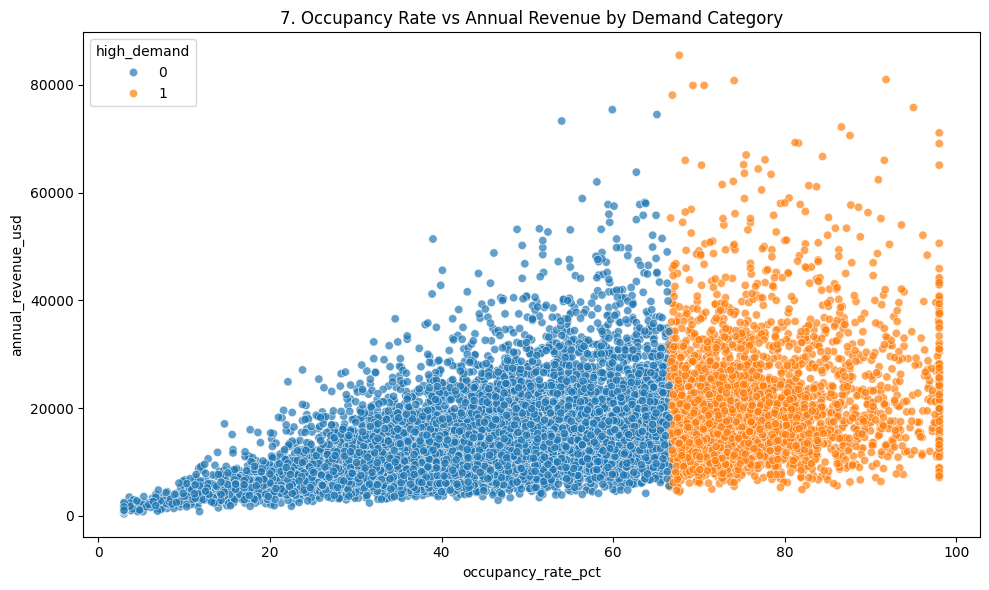

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='occupancy_rate_pct', y='annual_revenue_usd', hue='high_demand', alpha=0.7)
plt.title(f'{plot_no}. Occupancy Rate vs Annual Revenue by Demand Category')
show_fig()
plot_no += 1

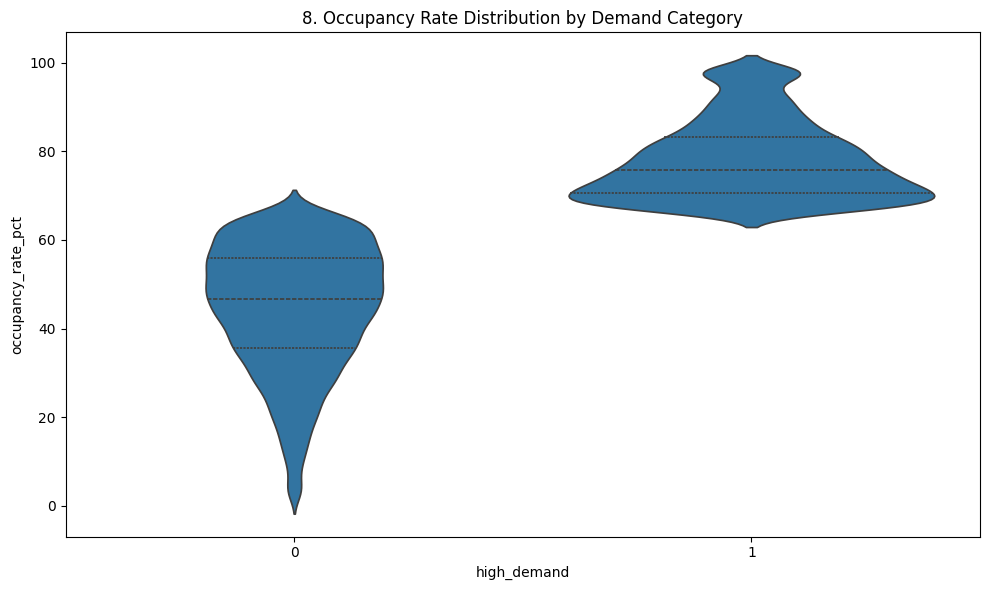

In [20]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='high_demand', y='occupancy_rate_pct', inner='quartile')
plt.title(f'{plot_no}. Occupancy Rate Distribution by Demand Category')
show_fig()
plot_no += 1

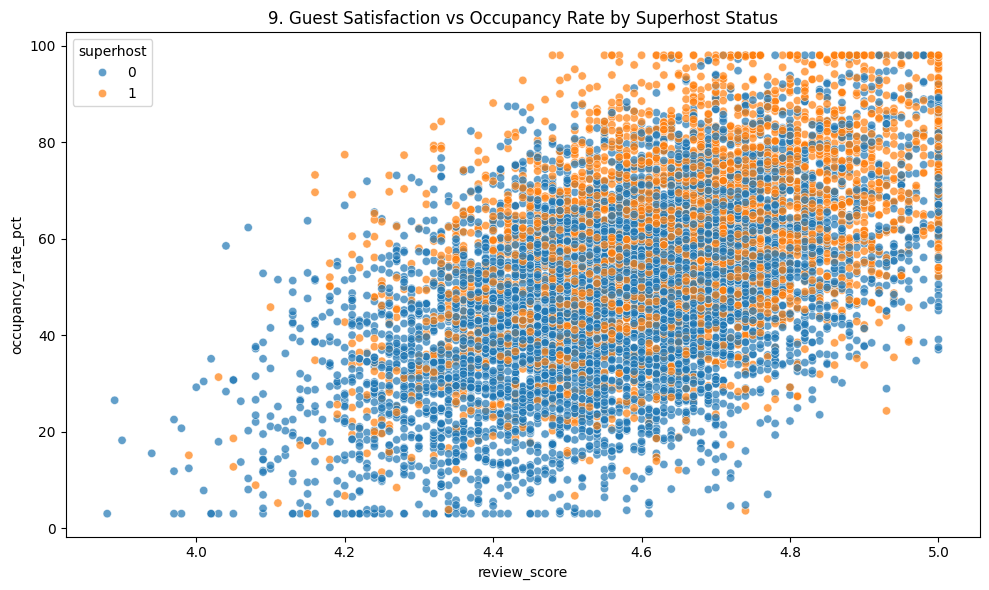

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='review_score', y='occupancy_rate_pct', hue='superhost', alpha=0.7)
plt.title(f'{plot_no}. Guest Satisfaction vs Occupancy Rate by Superhost Status')
show_fig()
plot_no += 1

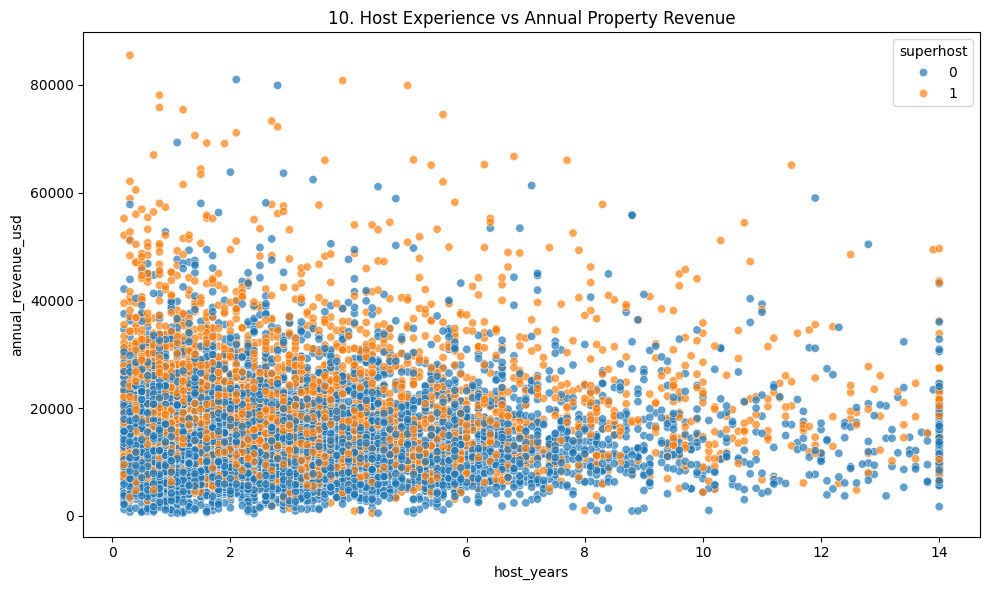

In [22]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='host_years', y='annual_revenue_usd', hue='superhost', alpha=0.7)
plt.title(f'{plot_no}. Host Experience vs Annual Property Revenue')
show_fig()
plot_no += 1

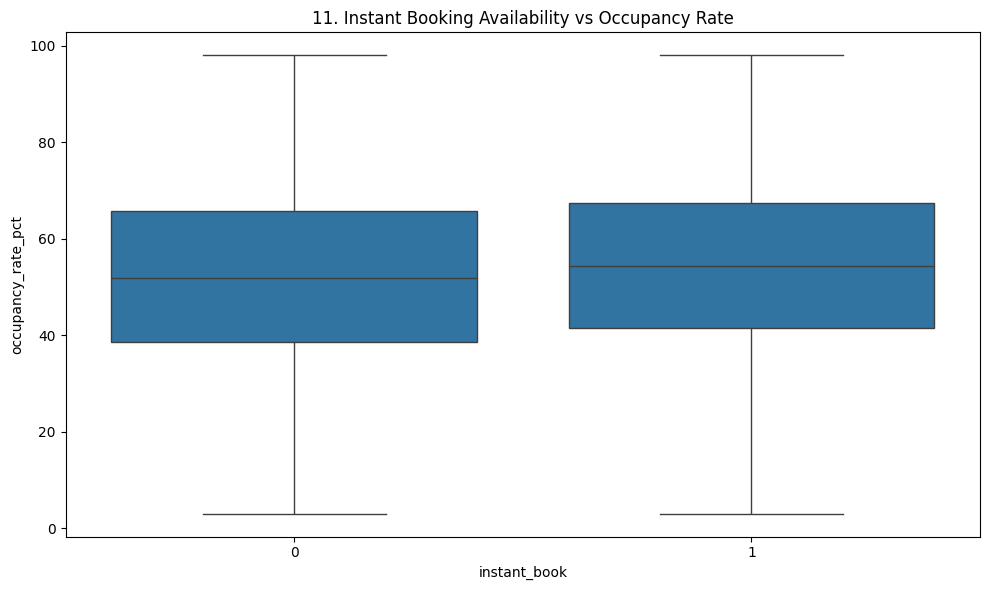

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='instant_book', y='occupancy_rate_pct')
plt.title(f'{plot_no}. Instant Booking Availability vs Occupancy Rate')
show_fig()
plot_no += 1

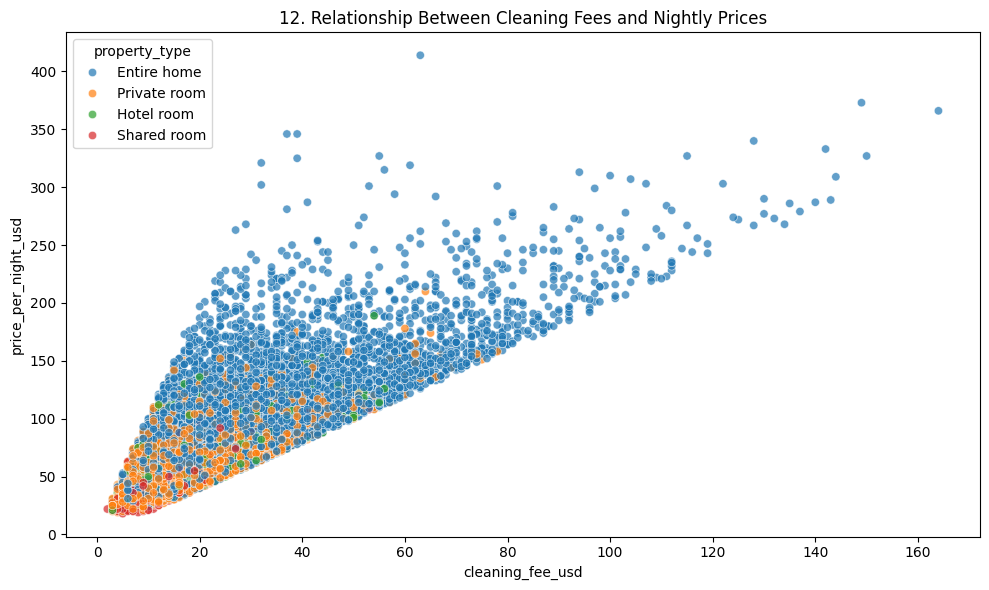

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='cleaning_fee_usd', y='price_per_night_usd', hue='property_type', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Cleaning Fees and Nightly Prices')
show_fig()
plot_no += 1

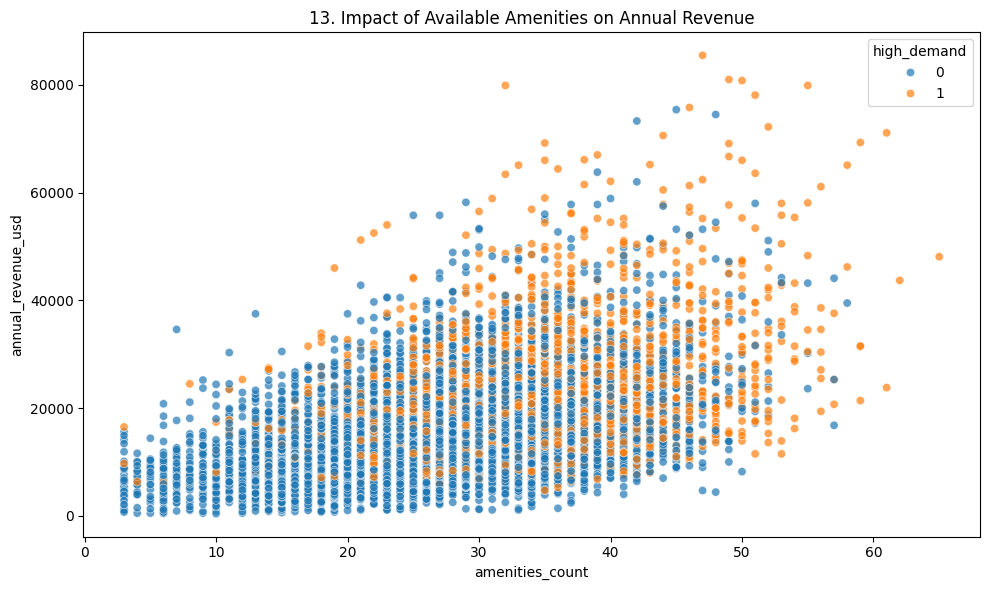

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='amenities_count', y='annual_revenue_usd', hue='high_demand', alpha=0.7)
plt.title(f'{plot_no}. Impact of Available Amenities on Annual Revenue')
show_fig()
plot_no += 1

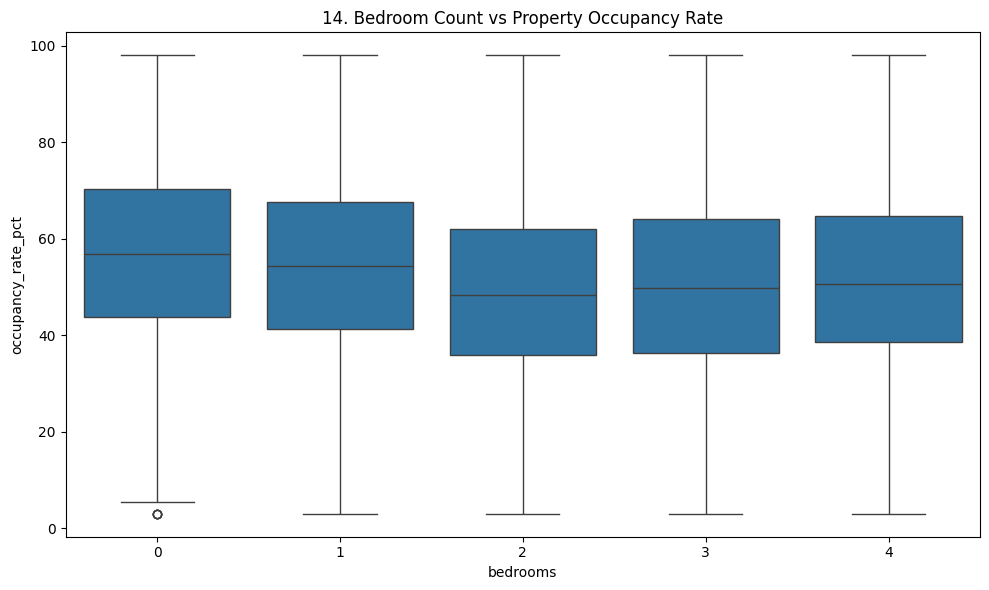

In [26]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='bedrooms', y='occupancy_rate_pct')
plt.title(f'{plot_no}. Bedroom Count vs Property Occupancy Rate')
show_fig()
plot_no += 1

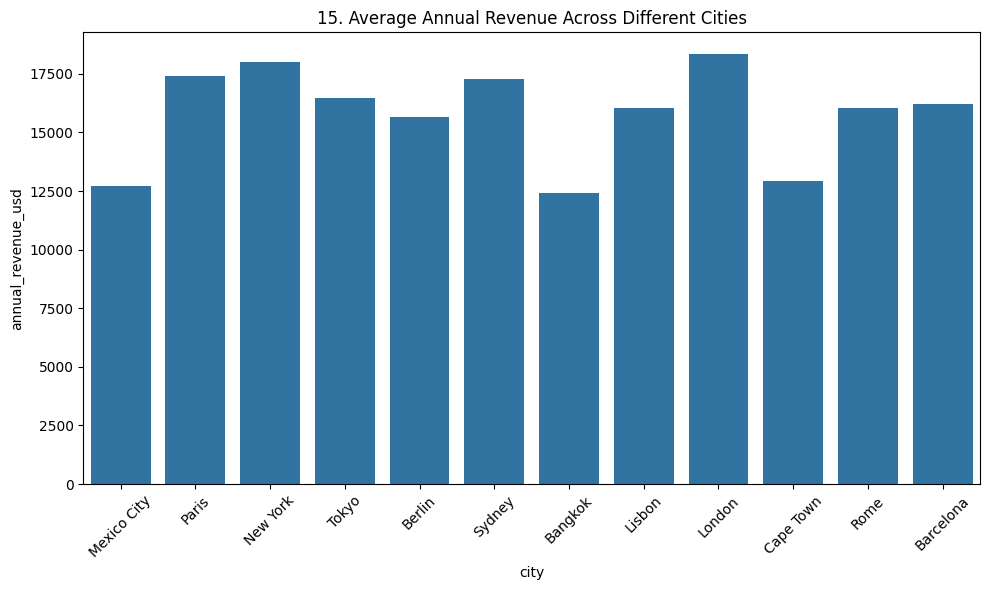

In [27]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='city', y='annual_revenue_usd', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Average Annual Revenue Across Different Cities')
show_fig()
plot_no += 1

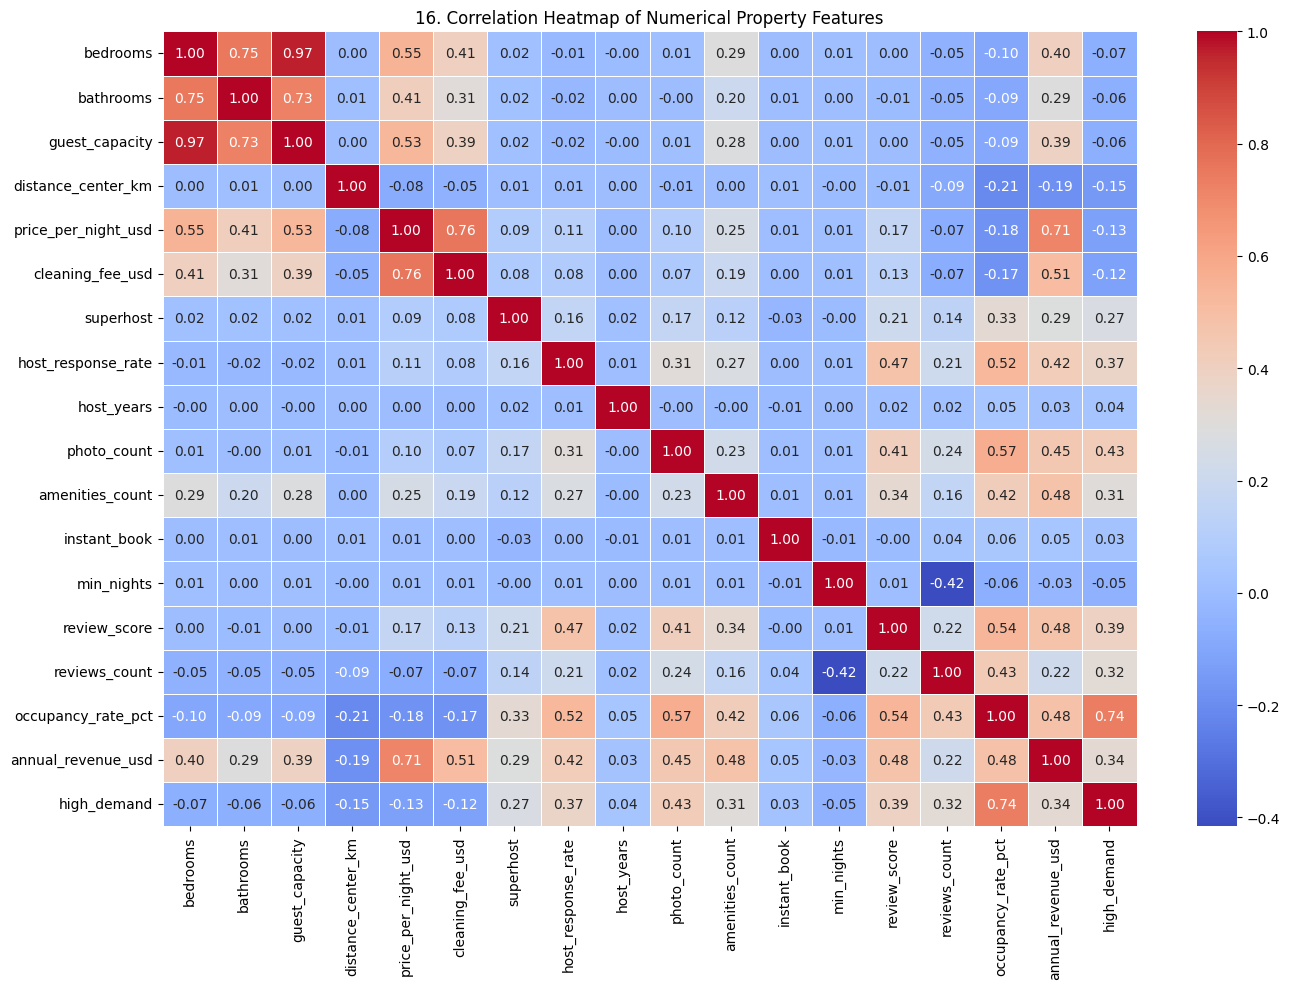

In [28]:
fig = plt.figure(figsize=(14,10))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Property Features')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [29]:
X = df.drop(columns=['high_demand', 'listing_id'], errors='ignore')
y = df['high_demand']

## Encode categorical features

In [30]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

for col in cat_cols:
    X[col] = X[col].fillna('Missing').astype(str)

## Handle missing numerical values

In [31]:
num_cols = X.select_dtypes(include=np.number).columns

for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

## Split dataset

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Train CatBoost classifier

In [33]:
model = CatBoostClassifier(
    iterations=1000,
    depth=8,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='Accuracy',
    auto_class_weights='Balanced',
    verbose=0,
    random_seed=42
)

model.fit(X_train, y_train, cat_features=cat_cols)

CatBoostClassifier(auto_class_weights='Balanced', depth=8, eval_metric='Accuracy', iterations=1000, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=0)

## Make predictions

In [34]:
y_pred = model.predict(X_test).ravel()

## Evaluate model

In [35]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model Accuracy: 100.00%

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



## Plot confusion matrix

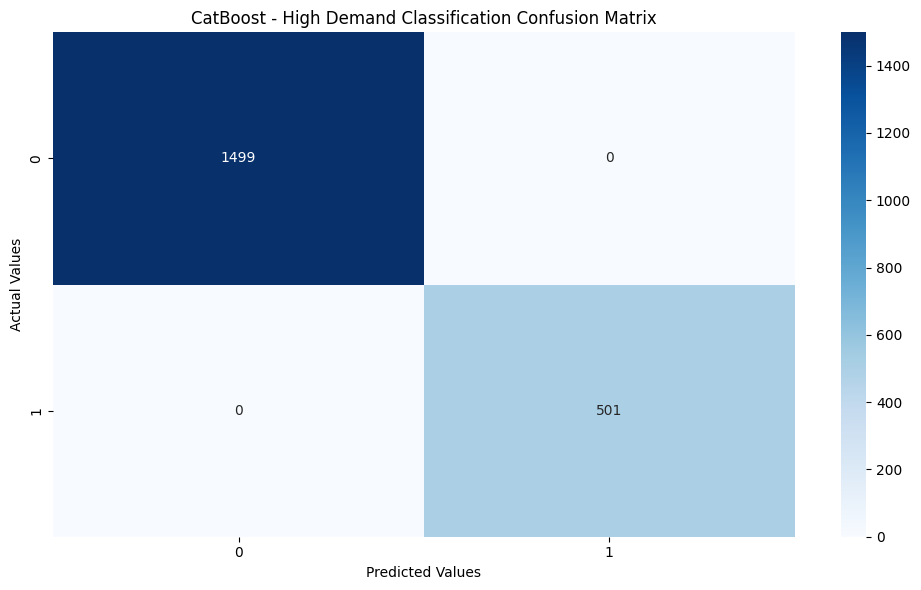

In [36]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('CatBoost - High Demand Classification Confusion Matrix')
show_fig()